In [97]:
import pandas as pd
from astropy.io import fits
import numpy as np
from astropy.table import Table
import matplotlib.pyplot as plt
import subprocess
import os
from math import sin, cos, tan, radians, sqrt, pi
from os.path import join
from matplotlib.pylab import *
from scipy import stats
from scipy.stats import ks_2samp
import seaborn as sns
from scipy.optimize import curve_fit
import math
from astropy.wcs import WCS
from astropy import units as u
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MultipleLocator, FuncFormatter
from numpy.random import *
from scipy.spatial import cKDTree
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch

In [67]:
df = pd.read_csv('Full_cloud_catalogue_arms.csv')

M = df['X-mass']
s = df['sigv_kms']
d = df['final_distance']
l = df['x_cen']

semi_major_deg= df['major_arcsec'] / 3600  # Divide by 3600, major arcsec is semi, actually!
semi_minor_deg= df['minor_arcsec'] / 3600

semi_major_pc = semi_major_deg * d * np.pi / 180 * 2.354 / 2 # HWHM
semi_minor_pc = semi_minor_deg * d * np.pi / 180 * 2.354 / 2 

R = (semi_major_pc *semi_minor_pc)**(1/2)  * 1000

df['radius'] = R

surface_density = M /np.pi / R**2

df['surface_density'] = surface_density

#mask_comp = (M / d ** 2 > 75.7)
mask_comp = (M > 10 ** 4)
mask_lon1 = (l > 10) & (l < 50)
mask_lon2 = (l > 310) & (l < 350)
mask_vald = (M > 0) & (R > 0) & (d > 0)


science_mask =  mask_comp & (mask_lon1 | mask_lon2) & mask_vald
df_ss = df[science_mask]

Ms = df_ss['X-mass']
ss = df_ss['sigv_kms']
ds = df_ss['final_distance']
ls = df_ss['x_cen']
Rs = df_ss['radius']


df_F = df[(mask_comp) & (mask_lon1)]
df_M = df[(mask_comp) & (mask_lon2)]


df = df[mask_vald]
M = df['X-mass']
s = df['sigv_kms']
d = df['final_distance']
R = df['radius']

# Assign cloud coordinates
l = np.radians(df["x_cen"].to_numpy())  ## This l overwrites the one above and is in radians
b = np.radians(df["y_cen"].to_numpy())
d = df["final_distance"].to_numpy()

R0 = 8.15
X = d * np.cos(b) * np.sin(l)
Y = R0 - d * np.cos(b) * np.cos(l)

Rg = np.hypot(X, Y)

# Reid azimuth convention
beta = np.degrees(np.arctan2(X, Y))

df["X_kpc"] = X
df["Y_kpc"] = Y

In [68]:
df.columns

Index(['Universal_ID', '_idx', 'position_angle', 'v_cen', 'x_cen', 'y_cen',
       'sigv_kms', 'major_arcsec', 'minor_arcsec', 'has_match',
       'AGAL_distance', 'R_GC', 'd_near', 'd_far', 'distance',
       'total_flux_13CO', 'pixel_number_13CO', 'final_distance',
       'M_pixel_Sol_13CO', 'total_flux_12CO', 'pixel_number_12CO',
       'M_pixel_Sol_12CO', 'pixel_number_LTE', 'LTE_Density', 'M_LTE_Sol',
       'Tex_weighted', 'Tex_median', 'X-mass', 'X-pixels', 'X-flux',
       'FGN_flag', 'nearest_arm', 'arm_distance_kpc', 'assigned_arm', 'radius',
       'surface_density', 'X_kpc', 'Y_kpc'],
      dtype='str')

In [69]:
## Create Reid arms
def reid_arm(name, n=2000, extend_low=0, extend_high=0,
             params=None):

    if params is None:
        params = parameters

    bmin, bmax, bkink, Rkink, p_low, p_high = params[name]

    beta = np.linspace(
        bmin - extend_low,
        bmax + extend_high,
        n
    )

    pitch = np.where(beta <= bkink, p_low, p_high)

    Rg = Rkink * np.exp(
        -np.radians(beta - bkink)
        * np.tan(np.radians(pitch))
    )

    X = Rg * np.sin(np.radians(beta))
    Y = Rg * np.cos(np.radians(beta))

    original = (beta >= bmin) & (beta <= bmax)

    return {
        "beta": beta,
        "R": Rg,
        "X": X,
        "Y": Y,
        "original": original
    }

parameters = {
    "3-kpc":   (15, 18, 15, 3.52, -4.2, -4.2),
    "Norma":   (5, 54, 18, 4.46, -1.0, 19.5),
    "Sct-Cen": (0, 104, 23, 4.91, 14.1, 12.1),
    "Sgr-Car": (2, 97, 24, 6.04, 17.1, 1.0),
    "Local":   (-8, 34, 9, 8.26, 11.4, 11.4),
    "Perseus": (-23, 115, 40, 8.87, 10.3, 8.7),
    "Outer":   (-16, 71, 18, 12.24, 3.0, 9.4),
}

arm_names = ["Norma", "Sct-Cen", "Sgr-Car", "Perseus", "3-kpc"]

colours = {
    "Norma": "red",
    "Sct-Cen": "blue",
    "Sgr-Car": "purple",
    "Perseus": "black",
    "3-kpc": "orange"
}

# Generate all four arms
extended_arms = {
    name: reid_arm(
        name,
        extend_low  = 130,
        extend_high =130
    )
    for name in arm_names
}

In [70]:
## Asign Vlsr to extended Reid arms

Theta0 = 236.0     # km/s

# Brand & Blitz (1993) coefficients
a1 = 1.00767
a2 = 0.0394
a3 = 0.00712

def brand_blitz(R):
    ratio = R / R0

    # Normalize so Theta(R0) = Theta0
    return Theta0 * (
        (a1 * ratio**a2 + a3) / (a1 + a3)
    )


for name, arm in extended_arms.items():

    X = np.asarray(arm["X"])
    Y = np.asarray(arm["Y"])

    # Galactocentric radius
    Rg = np.asarray(arm['R'])

    # Galactic longitude (degrees)
    l = np.degrees(
        np.arctan2(X, R0 - Y)
    ) % 360

    # Circular rotation velocity
    Theta = brand_blitz(Rg)

    # Line-of-sight velocity relative to LSR
    V_lsr = (
        Theta * R0 / Rg - Theta0
    ) * np.sin(np.radians(l))

    # Add results to dictionary
    arm["R"] = Rg
    arm["l"] = l
    arm["Theta"] = Theta
    arm["V_lsr"] = V_lsr

In [71]:
# Build a KD-tree for each spiral arm and assign arms in lv space
arm_trees = {}

arm_widths = {
    "Norma": 0.14,
    "Sct-Cen" : 0.23,
    "Sgr-Car" : 0.27,
    "Perseus" : 0.35,
    "3-kpc"   : 0.18
}

for name, arm in extended_arms.items():

    xy = np.column_stack([
        arm["X"],
        arm["Y"]
    ])

    arm_trees[name] = cKDTree(xy)


# Assign clouds using spatial + velocity criteria
assignments = []
velocity_differences = []
nearest_arm_velocities = []

for i in range(len(df)):

    arm_name = df["nearest_arm"].iloc[i]

    # Check that the nearest arm exists
    if arm_name not in extended_arms:
        assignments.append("Unassigned")
        velocity_differences.append(np.nan)
        nearest_arm_velocities.append(np.nan)
        continue

    arm = extended_arms[arm_name]

    # Cloud position
    cloud_xy = [
        df["X_kpc"].iloc[i],
        df["Y_kpc"].iloc[i]
    ]

    # Find closest point along the spiral arm
    distance, idx = arm_trees[arm_name].query(cloud_xy)

    # Predicted arm velocity at that point
    arm_velocity = arm["V_lsr"][idx]

    # Observed cloud velocity
    cloud_velocity = df["v_cen"].iloc[i] / 1000

    # Velocity difference
    delta_v = abs(cloud_velocity - arm_velocity)


    # Both criteria must be satisfied
    if distance < 0.3 and delta_v < 10:
    #if distance < arm_widths[arm_name] and delta_v < 10:

        assignments.append(arm_name)

    else:

        assignments.append("Unassigned")

    velocity_differences.append(delta_v)
    nearest_arm_velocities.append(arm_velocity)


# Save results
df["assigned_arm"] = assignments
df["arm_velocity"] = nearest_arm_velocities
df["velocity_difference"] = velocity_differences

mask_asgn = (df['assigned_arm'] != "Unassigned")
df_arm = df[(mask_comp) & (mask_asgn)]
df_uns = df[(mask_comp) & ~(mask_asgn)]

In [ ]:
## Old spatial assignment code, keep it around just in case lv fails

assignments = []

for i in range(len(df)):
    for arm in arm_widths:
        if df['nearest_arm'].loc[i] != arm:
            continue
        else:
           # if df['arm_distance_kpc'].loc[i] < arm_widths[arm]:
            if df['arm_distance_kpc'].loc[i] < 0.3:

                assignments.append(arm)
            else:
                assignments.append('Unassigned')

df['assigned_arm'] = assignments

In [72]:
arms_df = pd.concat([
    pd.DataFrame({
        "arm": name,
        "x_cen": arm["l"],
        "y_cen": np.zeros(len(arm["l"])),
        "v_cen": arm["V_lsr"],
        "X": arm["X"],
        "Y": arm["Y"]
    })
    for name, arm in extended_arms.items()
], ignore_index=True)

arms_df.to_csv("extended_Reid_arms_lv.csv", index=False)

print(f"Saved {len(arms_df)} arm points.")

Saved 10000 arm points.


In [73]:
df[(df['assigned_arm'] == "Unassigned") & (df['nearest_arm'] == "3-kpc") & (df['arm_distance_kpc'] < 0.3)][['Universal_ID', 'nearest_arm', 'arm_distance_kpc', 'v_cen', 'arm_velocity', 'velocity_difference']].sort_values(by = 'velocity_difference')

,Universal_ID,nearest_arm,arm_distance_kpc,v_cen,arm_velocity,velocity_difference
1556,1557,3-kpc,0.060046,-83053.99,-93.777190,10.723200
426,427,3-kpc,0.056442,97442.53,108.536985,11.094455
409,410,3-kpc,0.035620,98756.45,111.054721,12.298271
412,413,3-kpc,0.070827,101357.95,113.739377,12.381427
437,438,3-kpc,0.039999,99338.99,111.773042,12.434052
398,399,3-kpc,0.136581,87106.52,100.245642,13.139122
447,448,3-kpc,0.137547,105875.33,119.311708,13.436378
425,426,3-kpc,0.056752,94663.43,108.536985,13.873555
461,462,3-kpc,0.181030,105689.65,120.143781,14.454131
328,329,3-kpc,0.222240,84346.64,98.852018,14.505378


In [74]:
special = (df['assigned_arm'] == "Unassigned") & (df['nearest_arm'] == "3-kpc") & (df['arm_distance_kpc'] < 0.3)

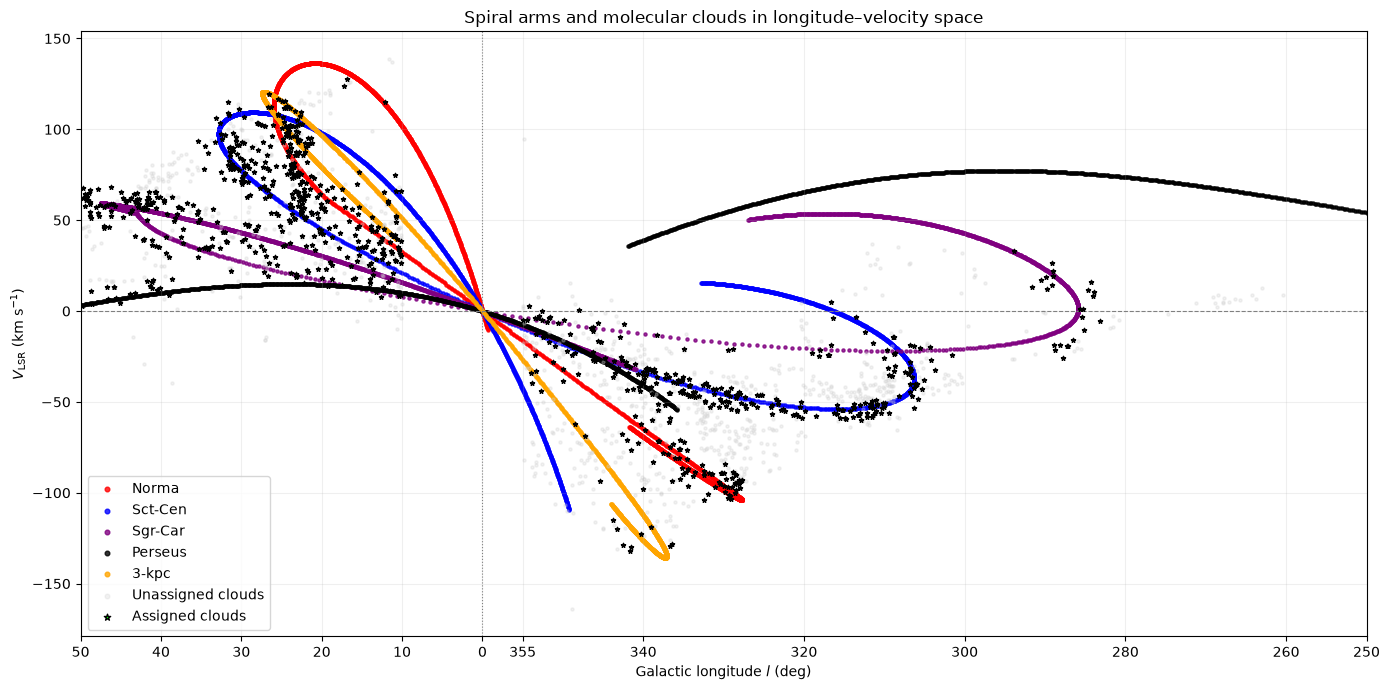

In [125]:
fig, ax = plt.subplots(figsize=(14, 7))

# ----- Spiral arms -----
for name, arm in extended_arms.items():

    l = np.asarray(arm["l"])
    v = np.asarray(arm["V_lsr"])

    # Convert 180-360 degrees to negative longitudes
    l_plot = (l + 180) % 360 - 180

    ax.scatter(
        l_plot,
        v,
        s=5,
        color=colours.get(name, "grey"),
        alpha=0.8,
        label=name
    )

# ----- Molecular clouds -----
cloud_l = np.degrees(
    np.arctan2(
        df["X_kpc"].to_numpy(),
        R0 - df["Y_kpc"].to_numpy()
    )
) % 360

cloud_l_plot = (cloud_l + 180) % 360 - 180

unassigned = df["assigned_arm"] == "Unassigned"
assigned = ~unassigned

ax.scatter(
    cloud_l_plot[unassigned],
    df.loc[unassigned, "v_cen"]/1000,
    s=5,
    color="lightgrey",
    alpha=0.3,
    label="Unassigned clouds",
    zorder=1
)

ax.scatter(
    cloud_l_plot[assigned],
    df.loc[assigned, "v_cen"]/1000,
    s=10,
    marker="*",
    color="lime",
    edgecolor="black",
    label="Assigned clouds",
    zorder=10
)

#ax.scatter(
#    cloud_l_plot[special],
#    df.loc[special, "v_cen"]/1000,
#    s=100,
#    marker="*",
#    color="lime",
#    edgecolor="black",
#    label="Special clouds",
#    zorder=10
#)

# ----- Axes -----
ax.set_xlim(50, -110)

# Display longitudes in the original 0-360 convention
ticks = [50, 40, 30, 20, 10, 0, -5, -20, -40, -60, -80, -100, -110]
tick_labels = [str(t % 360) for t in ticks]

ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)

ax.axhline(0, color="grey", ls="--", lw=0.8)
ax.axvline(0, color="grey", ls=":", lw=0.8)

ax.set_xlabel(r"Galactic longitude $l$ (deg)")
ax.set_ylabel(r"$V_{\mathrm{LSR}}$ (km s$^{-1}$)")
ax.set_title("Spiral arms and molecular clouds in longitude–velocity space")

ax.grid(alpha=0.2)
ax.legend(markerscale=1.5)

plt.tight_layout()
plt.show()

In [62]:
df.to_csv('Final_cloud_catalogue_arm_assignment_lv_03pc_10kms.csv')

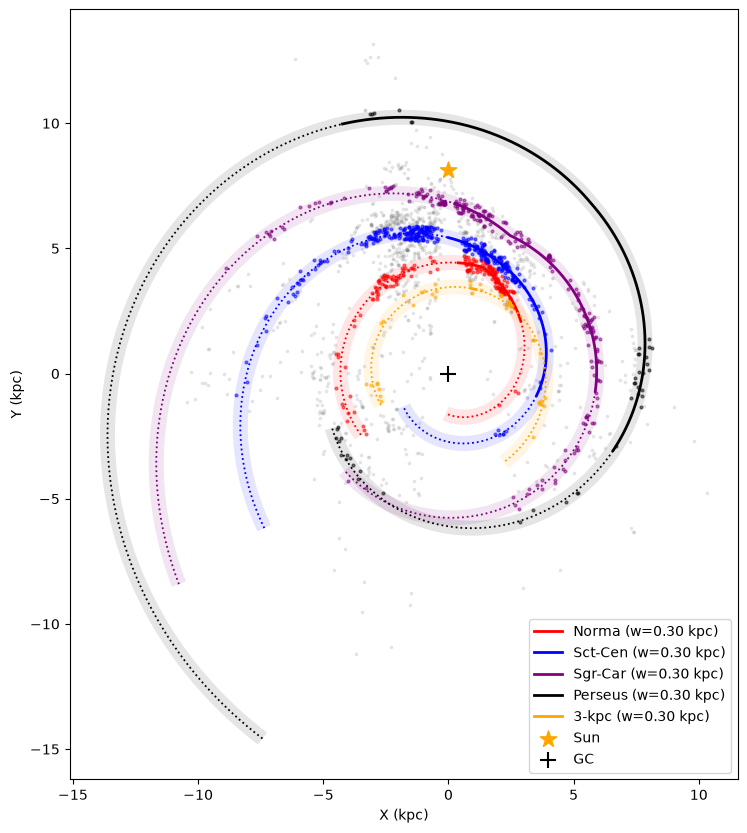

In [76]:
# Plot arms assignment ver.1

fig, ax = plt.subplots(figsize=(10, 10))

for name, arm in extended_arms.items():

    beta = arm["beta"]
    X = arm["X"]
    Y = arm["Y"]

    bmin, bmax, *_ = parameters[name]

    original = (beta >= bmin) & (beta <= bmax)
    extension_low = beta < bmin
    extension_high = beta > bmax

    # Arm width (kpc)
    #w = arm_widths[name]
    w = 0.3

    # Tangent vector along the spiral
    dx = np.gradient(X)
    dy = np.gradient(Y)

    length = np.hypot(dx, dy)

    # Unit normal vector
    nx = -dy / length
    ny = dx / length

    # Boundaries at +/- one arm width
    X_upper = X + w * nx
    Y_upper = Y + w * ny

    X_lower = X - w * nx
    Y_lower = Y - w * ny

    # Fill the band between the two boundaries
    band_x = np.concatenate([X_upper, X_lower[::-1]])
    band_y = np.concatenate([Y_upper, Y_lower[::-1]])

    ax.fill(
        band_x,
        band_y,
        color=colours[name],
        alpha=0.10,
        linewidth=0,
        zorder=1
    )

    # Original arm centreline
    ax.plot(
        X[original],
        Y[original],
        color=colours[name],
        lw=2,
        ls="-",
        label=f"{name} (w={w:.2f} kpc)",
        zorder=3
    )

    # Plot extensions separately to avoid artificial connections
    for mask in [extension_low, extension_high]:

        ax.plot(
            X[mask],
            Y[mask],
            color=colours[name],
            lw=1.3,
            ls=":",
            zorder=3
        )

# Catalogue clouds, coloured by assigned arm
for name in arm_names:

    subset = df[df["assigned_arm"] == name]

    ax.scatter(
        subset["X_kpc"],
        subset["Y_kpc"],
        s=4,
        color=colours[name],
        alpha=0.5,
        rasterized=True,
        zorder=4
    )

# Unassigned clouds
unassigned = df[df["assigned_arm"] == "Unassigned"]

ax.scatter(
    unassigned["X_kpc"],
    unassigned["Y_kpc"],
    s=3,
    color="grey",
    alpha=0.15,
    rasterized=True,
    zorder=2
)

# Sun and Galactic Centre
ax.scatter(0, R0, marker="*", s=150,
           color="orange", zorder=5, label="Sun")

ax.scatter(0, 0, marker="+", s=120,
           color="black", zorder=5, label="GC")

ax.set_xlabel("X (kpc)")
ax.set_ylabel("Y (kpc)")
ax.set_aspect("equal")
ax.legend()

plt.show()

Best-fit parameters: c = 0.0110, a = 0.4140, b = 1.4511
Best-fit parameters: c = 0.3070, a = 0.5676, b = 1.2643


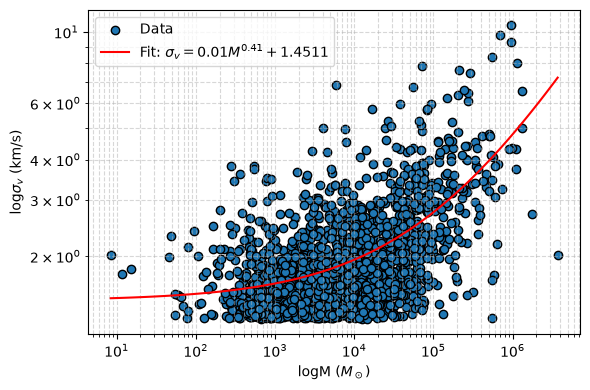

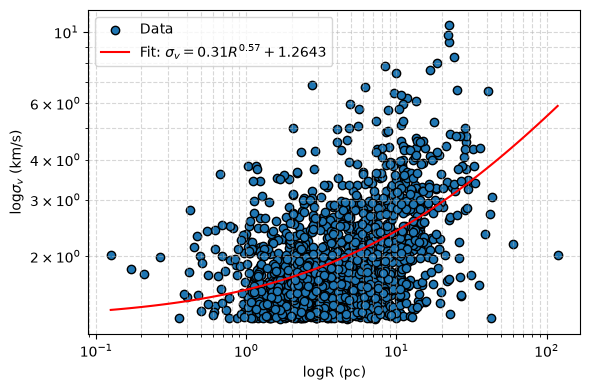

In [77]:
def power_law(M, c, a , b):
    return c * M**a +b

popt, pcov = curve_fit(power_law, M, s)
c_fit, a_fit, b_fit = popt

# Print results
print(f"Best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}, b = {b_fit:.4f}")

# Plot the data and the fit
M_fit = np.logspace(np.log10(max(1,min(M))), np.log10(max(M)), 100)
s_fit = power_law(M_fit, c_fit, a_fit, b_fit)

plt.figure(figsize=(6, 4))
plt.scatter(M, s, edgecolor='k', label = 'Data')
plt.plot(M_fit, s_fit, label=fr'Fit: $\sigma_v = {c_fit:.2f} M^{{{a_fit:.2f}}} +{b_fit:.4f}$', color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('logM ($M_\odot$)')
plt.ylabel(r'log$\sigma_v$ (km/s)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha = 0.5)
plt.tight_layout()
#plt.show()
#plt.savefig('Larson_mass_v_sigma_big_code.png')


popt, pcov = curve_fit(power_law, R, s)
c_fit, a_fit, b_fit = popt

# Print results
print(f"Best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}, b = {b_fit:.4f}")

# Plot the data and the fit
R_fit = np.logspace(np.log10(max(0.1,min(R))), np.log10(max(R)), 100)
s_fit = power_law(R_fit, c_fit, a_fit, b_fit)

plt.figure(figsize=(6, 4))
plt.scatter(R, s, edgecolor='k', label = 'Data')
plt.plot(R_fit, s_fit, label=fr'Fit: $\sigma_v = {c_fit:.2f} R^{{{a_fit:.2f}}}+{b_fit:.4f}$', color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('logR (pc)')
plt.ylabel(r'log$\sigma_v$ (km/s)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha = 0.5)
plt.tight_layout()
#plt.show()
#plt.savefig('Larson_radius_v_sigma_big_code.png')

Weighted fit: log(M) = 2.0963 * log(R) + 2.5636
Parameter errors: 2.0963 ± 0.0162, 2.5636 ± 0.0116


c = 1896.7114 ± 114.7210
a = 1.5900 ± 0.0141
Power law with constant best-fit parameters: c = 1896.7114, a = 1.5900


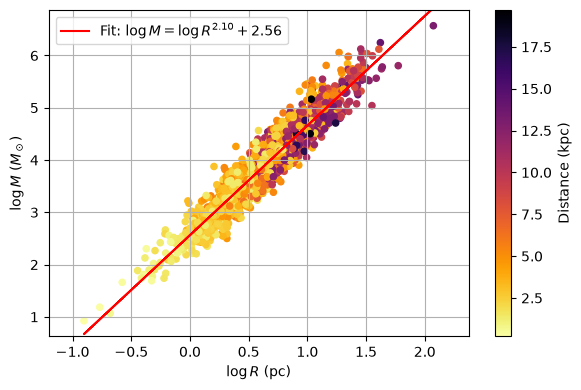

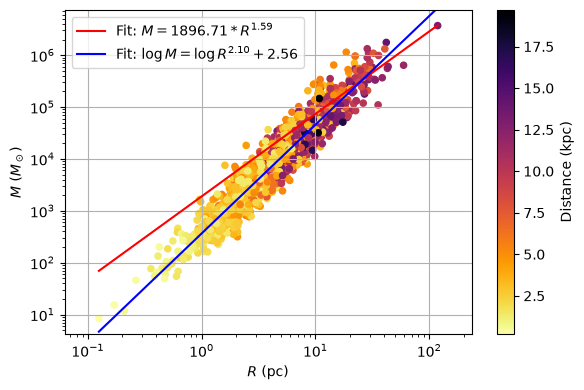

In [78]:
logR = np.log10(R)
logM = np.log10(M)
W = df['final_distance'].values

# Define weights (e.g., directly or 1/W if you want inverse-distance weight)
weights = W  # or 1/W, or 1/W**2 depending on purpose

x_range = [R.min()/2, R.max()*2]
y_range = [M.min()/2, M.max()*2]

# Weighted polyfit
fit, cov = np.polyfit(logR, logM, 1, cov=True) # Add w=weights in this if you want weight
a1_fit, c1_fit = fit

a_err, c_err = np.sqrt(np.diag(cov))

C1 = 10**c1_fit
C1_err = C1 * np.log(10) * c_err  # error propagation

print(f"Weighted fit: log(M) = {a1_fit:.4f} * log(R) + {c1_fit:.4f}")
print(f"Parameter errors: {a1_fit:.4f} ± {a_err:.4f}, {c1_fit:.4f} ± {c_err:.4f}")
    
# Plot
plt.figure(figsize=(6, 4))
plt.scatter(logR, logM, c=W, cmap='inferno_r', s=20)#, edgecolor='k')
plt.plot(logR, a1_fit * logR + c1_fit, color='red', label=fr'Fit: $\log M = \log R^{{{a1_fit:.2f}}} + {c1_fit:.2f}$')


plt.xlabel(r'$\log R$ (pc)')
plt.ylabel(r'$\log M$ ($M_\odot$)')
plt.xlim(np.log10(x_range))
plt.ylim(np.log10(y_range))
plt.legend()
plt.grid(True)
plt.colorbar(label='Distance (kpc)')
plt.tight_layout()
#plt.show()
#plt.savefig(destination_path +'FUGIN_13CO_Mass_radius_python.png')

## And a power law with an extra term

def power_law(R, c, a):
    return c * R**a

# Fit the model
popt, pcov = curve_fit(power_law, R, M,sigma = 1/weights, absolute_sigma=False)
c_fit, a_fit = popt
c_err, a_err = np.sqrt(np.diag(pcov))
print("\n")
print(
    f"c = {c_fit:.4f} ± {c_err:.4f}\n"
    f"a = {a_fit:.4f} ± {a_err:.4f}"
)
C2_err, a2_err = np.sqrt(np.diag(pcov))

                       
# Print results
print(f"Power law with constant best-fit parameters: c = {c_fit:.4f}, a = {a_fit:.4f}")

# Plot the data and the fit
R_fit = np.logspace(np.log10(min(R)), np.log10(max(R)), 500)
M_fit = power_law(R_fit, c_fit, a_fit)

plt.figure(figsize=(6, 4))
plt.scatter(R, M, c=W, cmap='inferno_r', s=20)#, edgecolor='k')
plt.plot(R_fit, M_fit, color='red', label=fr'Fit: $M = {c_fit:.2f}*R^{{{a_fit:.2f}}}$')
plt.plot(R_fit, 10**c1_fit*R_fit**a1_fit,color='blue', label = fr'Fit: $\log M = \log R^{{{a1_fit:.2f}}} + {c1_fit:.2f}$')

plt.xlabel(r'$R$ (pc)')
plt.ylabel(r'$M$ ($M_\odot$)')
plt.xscale('log')
plt.yscale('log')
plt.xlim(x_range)
plt.ylim(y_range)
plt.legend()
plt.grid(True)
plt.colorbar(label='Distance (kpc)')
plt.tight_layout()

Fitted parameters:
A = 7.9267e+05
a = -1.7835
χ^2 = 0.0240


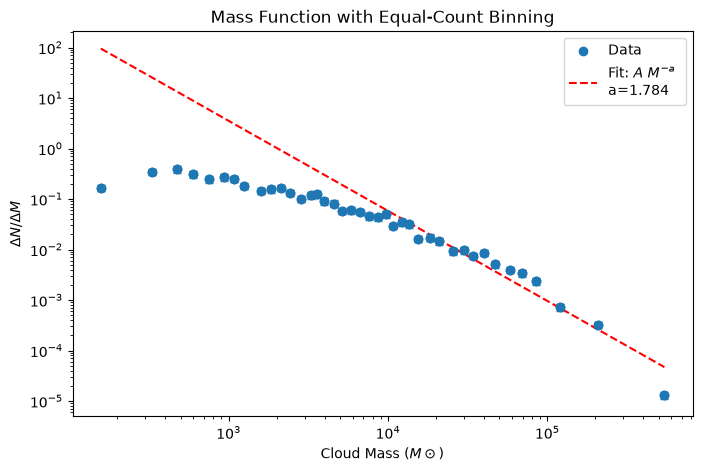

In [79]:
# Number of bins = ceil(2 * N^0.4)
N = len(M)
num_bins = math.ceil(2 * (N ** 0.4))   # same rule as before

# ----- 1. Sort values -----
sorted_vals = np.sort(M)

# ----- 2. Compute quantile bin edges (equal-count bins) -----
quantiles = np.linspace(0, 1, num_bins + 1)
bin_edges = np.quantile(sorted_vals, quantiles)

# Remove duplicate edges (can occur if many identical masses)
bin_edges = np.unique(bin_edges)

# Recompute num_bins in case duplicates removed
num_bins_actual = len(bin_edges) - 1

# ----- 3. Count values in each bin -----
counts = np.histogram(sorted_vals, bins=bin_edges)[0]

# ----- 4. Linear bin widths -----
bin_widths = bin_edges[1:] - bin_edges[:-1]

# ----- 5. Density = counts / linear width -----
density = counts / bin_widths
density_err = np.sqrt(counts) / bin_widths

# ----- 6. Show values inside each bin -----
bin_values = []  # list of arrays, one per bin

for i in range(num_bins_actual):
    left = bin_edges[i]
    right = bin_edges[i+1]

    # include left edge, exclude right edge (like numpy histogram)
    mask = (sorted_vals >= left) & (sorted_vals < right)
    vals_in_bin = sorted_vals[mask]

    # for the LAST bin, include the right edge too:
    if i == num_bins_actual - 1:
        mask = (sorted_vals >= left) & (sorted_vals <= right)
        vals_in_bin = sorted_vals[mask]

    bin_values.append(vals_in_bin)

# ----- 7. Median of each bin -----
bin_medians = np.array([np.median(vals) for vals in bin_values])


bin_medians_log = np.log10(bin_medians)

x_log = bin_medians_log[22:]  # This is for the entire dataset, could be 18 or 11, I'm not sure.
y = density[22:]              # This is for the entire dataset

# Convert density to log10
y_log = np.log10(y)

# --- Linear fit: y_log = B - a * x_log ---
coeffs, cov = np.polyfit(x_log, y_log, 1, cov=True)

slope = coeffs[0]      # this equals (-a)
intercept = coeffs[1]  # this equals log10(A)

# Extract A and a
a = slope
A = 10**intercept

predicted_values = A * (10**x_log)**(a)
linear_x2 = np.sum((y - predicted_values)**2/predicted_values)
fit_y = A * (10**bin_medians_log)**(a)

print("Fitted parameters:")
print(f"A = {A:.4e}")
print(f"a = {a:.4f}")
print(f"χ^2 = {linear_x2:.4f}")

# ----- 8. Scatter plot -----
plt.figure(figsize=(8,5))
plt.scatter(bin_medians, density, label ='Data')
plt.plot(bin_medians, fit_y, label=f"Fit: $A\ M^{{-a}}$ \na={-a:.3f}", linestyle="--",color='red')

plt.xlabel(f"Cloud Mass $(M\odot)$")
plt.ylabel(f"$\Delta N /\Delta M$")
plt.title("Mass Function with Equal-Count Binning")
plt.yscale('log')
plt.xscale('log')
plt.grid(True, which="both", ls="", alpha=0.2)
plt.errorbar(
    bin_medians,
    density,
    yerr=density_err,
    fmt='o',
    capsize=3
)
plt.legend()
plt.show()

Weighted fit: log(M) = 0.1248 * d + 3.1658


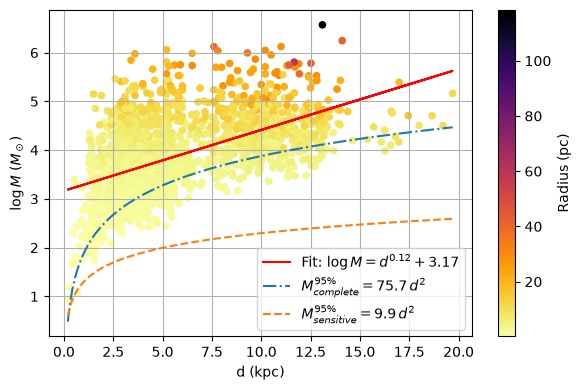

In [80]:
# Polyfit
fit = np.polyfit(d, logM, 1)
a_fit, c_fit = fit

# Completeness limit
d_model = np.linspace(d.min(),d.max(), int(len(d)/10))
M_complete = 75.7 * d_model ** 2
log_M_complete = np.log10(M_complete)

# Sensitivity
M_sens = 9.9 * d_model *2
log_M_sens = np.log10(M_sens)

print(f"Weighted fit: log(M) = {a_fit:.4f} * d + {c_fit:.4f}")

# Plot
plt.figure(figsize=(6, 4))
plt.scatter(d, logM, c=R, cmap='inferno_r', s=20)#, edgecolor='k')
plt.plot(d, a_fit * d + c_fit, color='red', label=fr'Fit: $\log M = d^{{{a_fit:.2f}}} + {c_fit:.2f}$')
plt.xlabel(r'd (kpc)')
plt.ylabel(r'$\log M$ ($M_\odot$)')
plt.grid(True)
plt.colorbar(label='Radius (pc)')
plt.plot(d_model, log_M_complete, linestyle = '-.', label=r'$M^{95\%}_{complete} = 75.7\, d^2$')
plt.plot(d_model, log_M_sens, linestyle = '--', label=r'$M^{95\%}_{sensitive} = 9.9\, d^2$')
plt.legend()
plt.tight_layout()
#plt.show()
#plt.savefig('/Users/kyriakos.trakakis/CHIMPS_FGN paper/FUGIN_13CO_Mass_distance_completeness_sensitivity.png')

mask_complete = (M > 75.7 * d**2)

(0.0, 47.81046789416969)

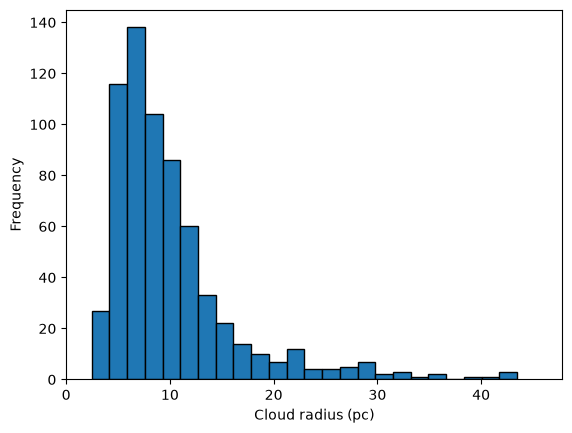

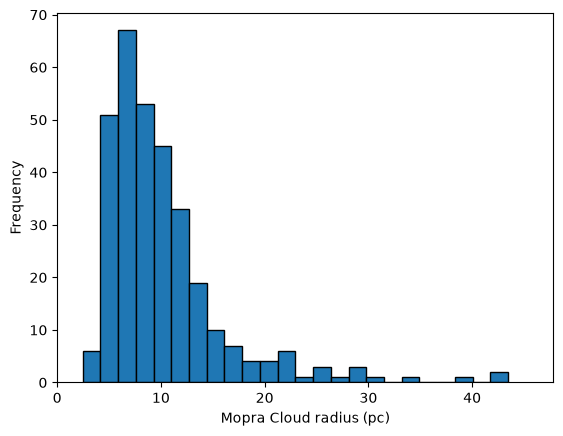

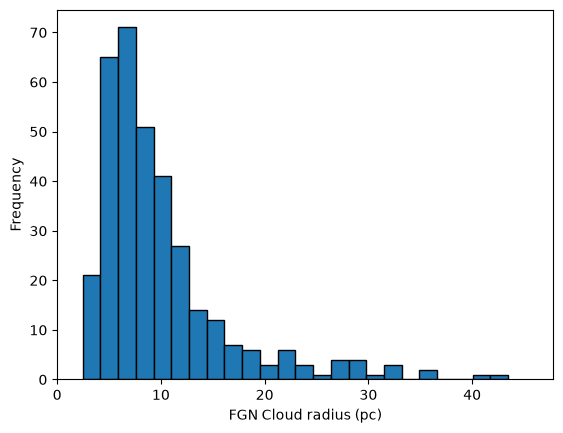

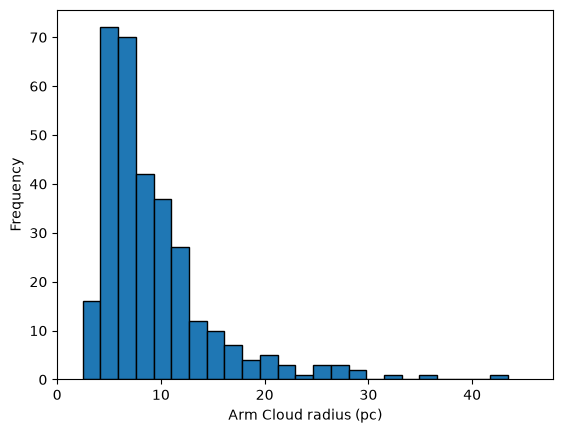

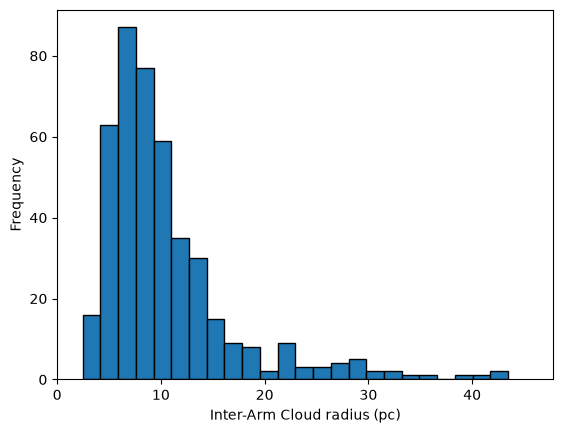

In [81]:
R_smaller = Rs[Rs < 50]  # With this we exclude 2 clouds, one at 59 pc and one at 118, same for both samples
xrange = [0, R_smaller.max() * 1.1]

bins = np.linspace(
        R_smaller.min(),
        R_smaller.max(),
        int(np.sqrt(len(R_smaller)))
)

plt.hist(R_smaller, bins = bins, edgecolor='k')
plt.xlabel('Cloud radius (pc)')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_M['radius'], bins = bins, edgecolor='k')
plt.xlabel('Mopra Cloud radius (pc)')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_F['radius'], bins = bins, edgecolor='k')
plt.xlabel('FGN Cloud radius (pc)')
plt.ylabel('Frequency')
plt.xlim(xrange) 

plt.figure()
plt.hist(df_arm['radius'], bins = bins, edgecolor='k')
plt.xlabel('Arm Cloud radius (pc)')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_uns['radius'], bins = bins, edgecolor='k')
plt.xlabel('Inter-Arm Cloud radius (pc)')
plt.ylabel('Frequency')
plt.xlim(xrange)

## I am not sure why the last one appears so chunky. Changing bins or dataset doesn't make a difference
## Using pretty bin definitions like below also does nothing.

## It is because I used bins that spanned to 40 pc for Mopra but to 120 pc for FGN.

(1.1545454545454545, 8.591000000000001)

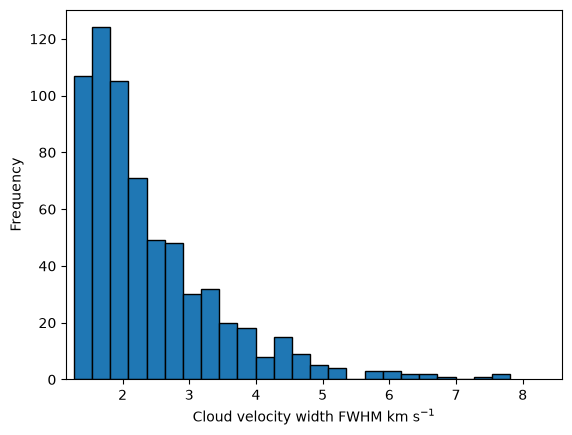

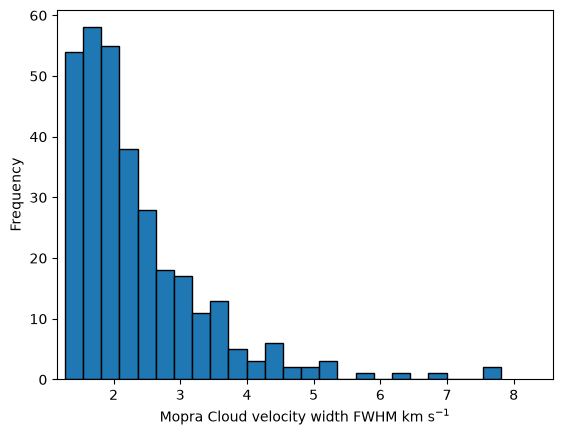

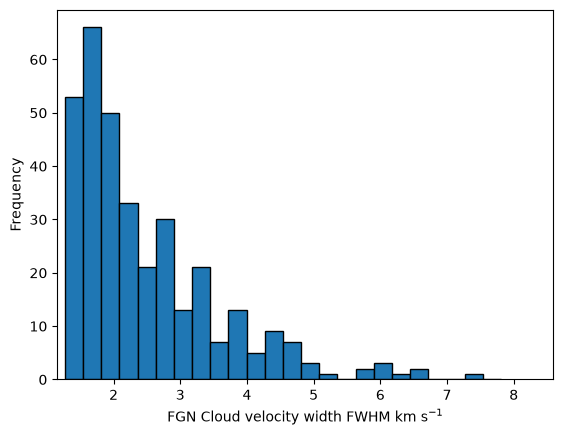

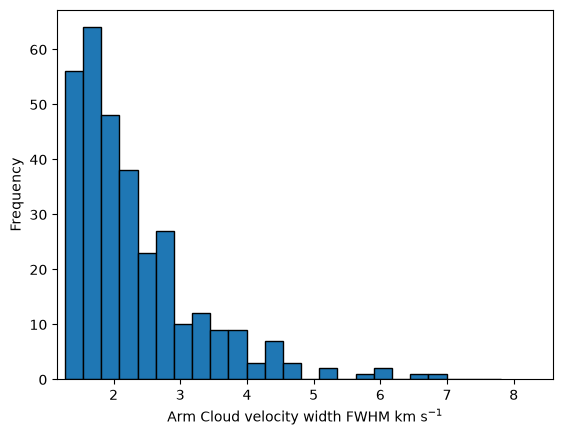

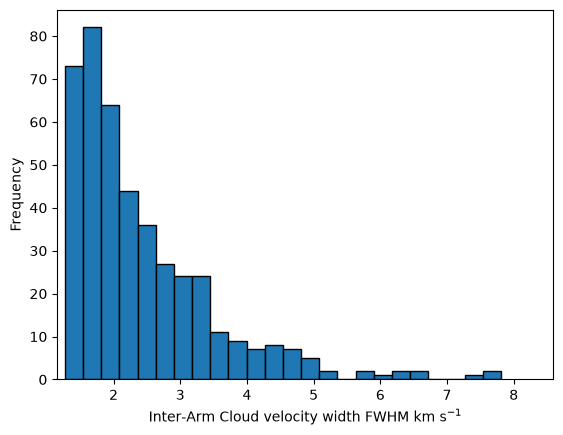

In [82]:
#destination_path = "/Users/kyriakos.trakakis/CHIMPS_FGN paper/"
s_small = ss[ss<8] # With this we exclude 5 clouds, for both total sample and science sample
xrange = [s_small.min() / 1.1, s_small.max() * 1.1]


bins = np.linspace(
        s_small.min(),
        s_small.max(),
        int(np.sqrt(len(s_small)))
)
plt.figure()
plt.hist(s_small, bins=bins, edgecolor='k')
plt.xlabel(r'Cloud velocity width FWHM km s$^{-1}$')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_M['sigv_kms'], bins=bins, edgecolor='k')
plt.xlabel(r'Mopra Cloud velocity width FWHM km s$^{-1}$')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_F['sigv_kms'], bins=bins, edgecolor='k')
plt.xlabel(r'FGN Cloud velocity width FWHM km s$^{-1}$')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_arm['sigv_kms'], bins=bins, edgecolor='k')
plt.xlabel(r'Arm Cloud velocity width FWHM km s$^{-1}$')
plt.ylabel('Frequency')
plt.xlim(xrange)

plt.figure()
plt.hist(df_uns['sigv_kms'], bins=bins, edgecolor='k')
plt.xlabel(r'Inter-Arm Cloud velocity width FWHM km s$^{-1}$')
plt.ylabel('Frequency')
plt.xlim(xrange)

#plt.savefig(destination_path + "fwhm_v_histogram.png")

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/2352562138.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/2352562138.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/2352562138.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/2352562138.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an undersco

(8416.666666666668, 4452000.0)

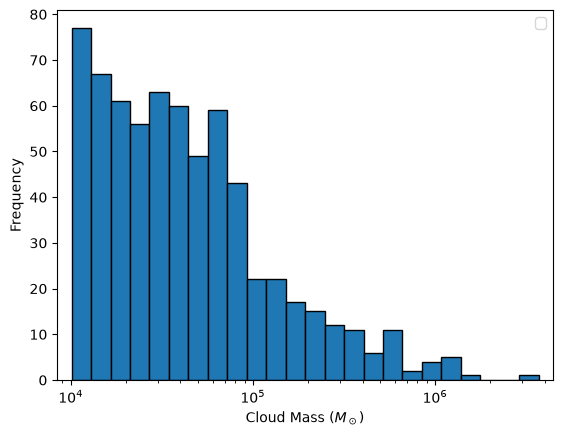

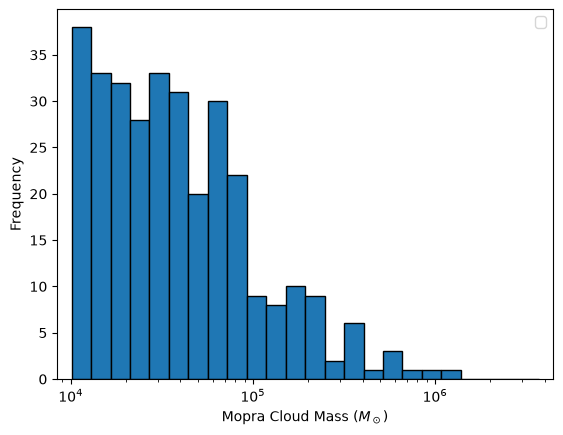

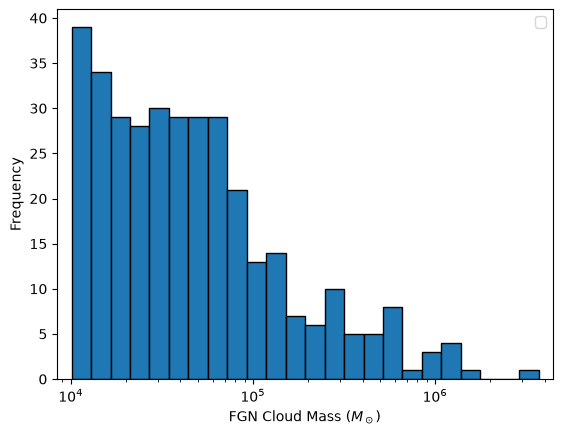

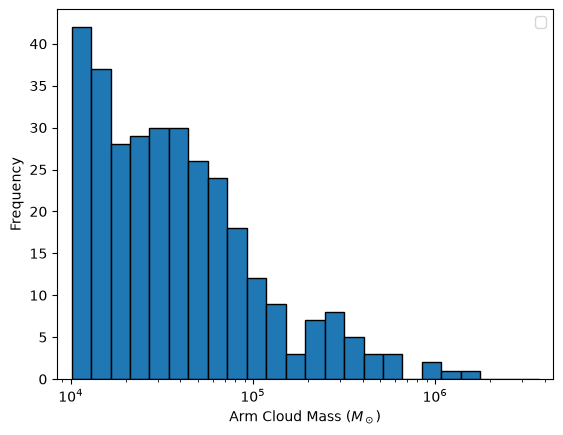

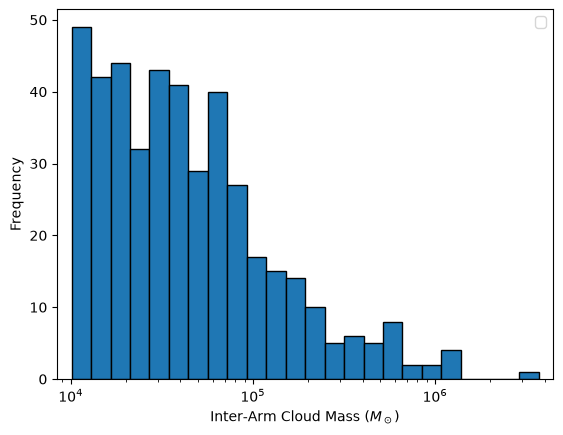

In [83]:
bins = np.logspace(
    np.log10(Ms.min()),
    np.log10(Ms.max()),
    int(np.sqrt(len(Ms)))
)
xrange = [Ms.min() / 1.2, Ms.max()* 1.2]

plt.hist(Ms, bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')
plt.legend()
plt.xlim(xrange)

plt.figure()
plt.hist(df_M['X-mass'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlabel(r'Mopra Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')
plt.legend()
plt.xlim(xrange)

plt.figure()
plt.hist(df_F['X-mass'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlabel(r'FGN Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')
plt.legend()
plt.xlim(xrange)

plt.figure()
plt.hist(df_arm['X-mass'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlabel(r'Arm Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')
plt.legend()
plt.xlim(xrange)

plt.figure()
plt.hist(df_uns['X-mass'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlabel(r'Inter-Arm Cloud Mass ($M_\odot$)')
plt.ylabel('Frequency')
plt.legend()
plt.xlim(xrange)


#plt.savefig(destination_path + "Mass_histogram.png")

Text(0, 0.5, 'Frequency')

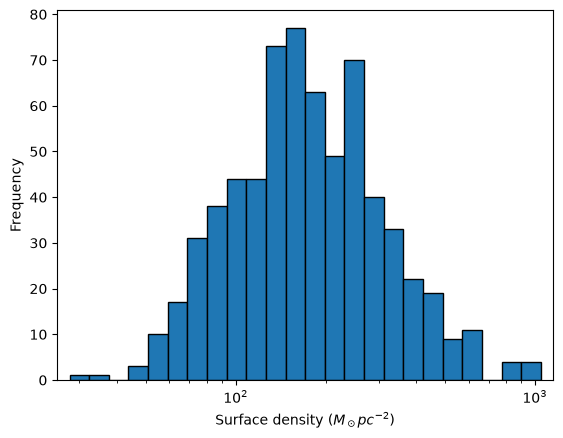

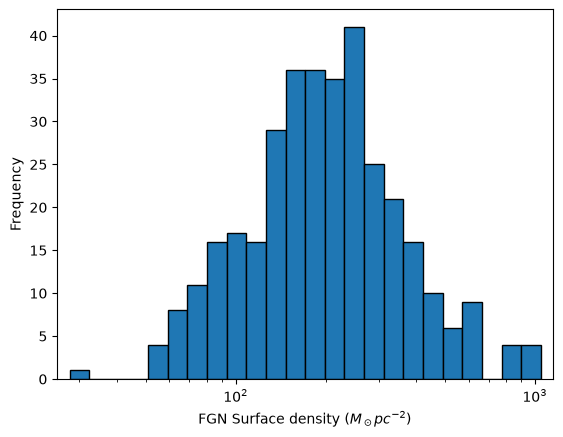

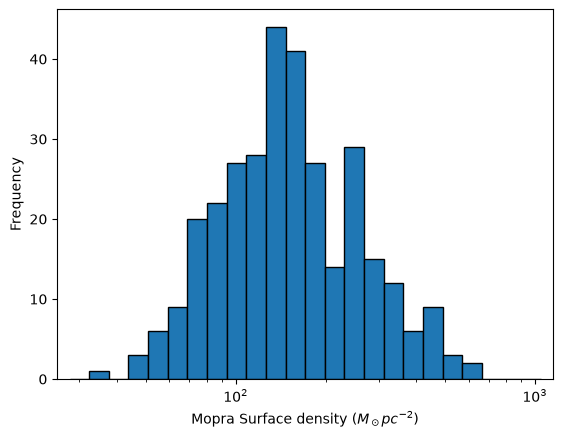

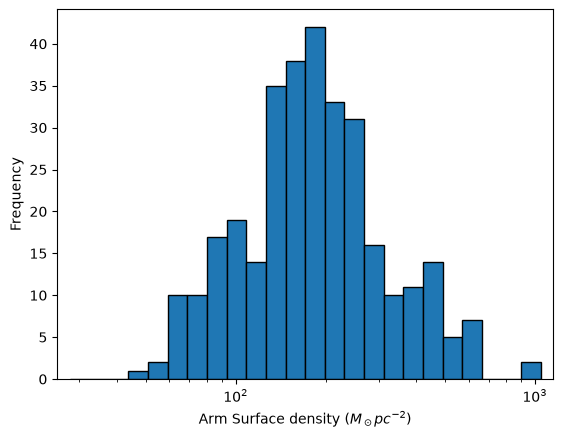

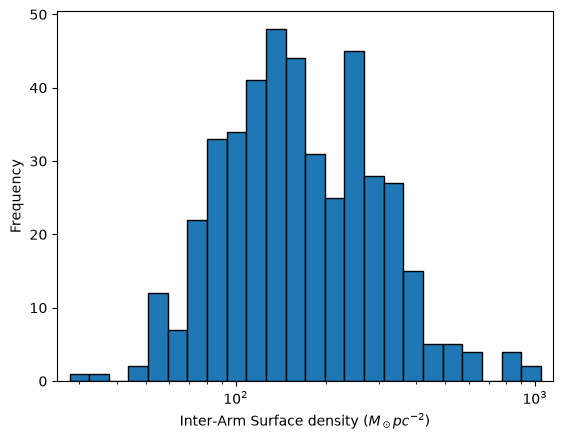

In [84]:
xrange = [df_ss['surface_density'].min() / 1.1, df_ss['surface_density'].max() * 1.1]

bins = np.logspace(
    np.log10(df_ss['surface_density'].min()),
    np.log10(df_ss['surface_density'].max()),
    int(np.sqrt(len(df_ss)))
)
plt.hist(df_ss['surface_density'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlim(xrange)
plt.xlabel(r'Surface density ($M_\odot pc^{-2}$)')
plt.ylabel('Frequency')

plt.figure()
plt.hist(df_F['surface_density'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlim(xrange)
plt.xlabel(r'FGN Surface density ($M_\odot pc^{-2}$)')
plt.ylabel('Frequency')

plt.figure()
plt.hist(df_M['surface_density'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlim(xrange)
plt.xlabel(r'Mopra Surface density ($M_\odot pc^{-2}$)')
plt.ylabel('Frequency')

plt.figure()
plt.hist(df_arm['surface_density'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlim(xrange)
plt.xlabel(r'Arm Surface density ($M_\odot pc^{-2}$)')
plt.ylabel('Frequency')

plt.figure()
plt.hist(df_uns['surface_density'], bins=bins, edgecolor='k')
plt.xscale('log')
plt.xlim(xrange)
plt.xlabel(r'Inter-Arm Surface density ($M_\odot pc^{-2}$)')
plt.ylabel('Frequency')

#plt.savefig(destination_path + "Surface_density_histogram_new.png")

KstestResult(statistic=np.float64(0.07632602610244665), pvalue=np.float64(0.27035369926899133), statistic_location=np.float64(37200.0), statistic_sign=np.int8(-1))


Text(0, 0.5, 'Mass CDF')

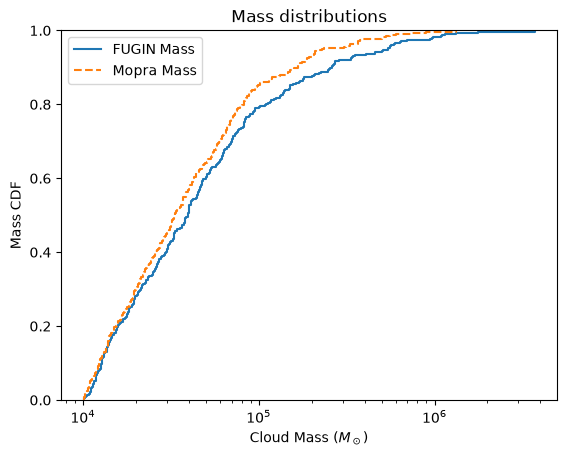

In [85]:
## Copied from BDC, I will use this to compare Mopra full X-factor vs Mopra full COLTE.
m = df_F['X-mass']
m2 = df_M['X-mass']

print(stats.kstest(m, m2))

plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label="FUGIN Mass",
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label="Mopra Mass",
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')

KstestResult(statistic=np.float64(0.06508568461139), pvalue=np.float64(0.39546210986386765), statistic_location=np.float64(54900.0), statistic_sign=np.int8(1))


Text(0, 0.5, 'Mass CDF')

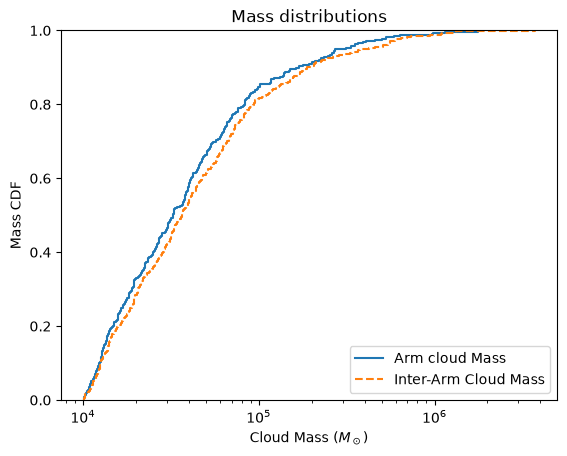

In [86]:
m = df_arm['X-mass']
m2 = df_uns['X-mass']
equal_ratio = m / m2

print(stats.kstest(m, m2))

plt.figure()
ax = sns.ecdfplot(
    m,
    log_scale=True,
    label="Arm cloud Mass",
    linestyle='-'
)

sns.ecdfplot(
    m2,
    log_scale=True,
    label="Inter-Arm Cloud Mass",
    linestyle='--',
    ax=ax
)
plt.title('Mass distributions')
plt.legend()

plt.xlabel(r'Cloud Mass ($M_\odot$)')
plt.ylabel('Mass CDF')

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/502208519.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/502208519.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/502208519.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


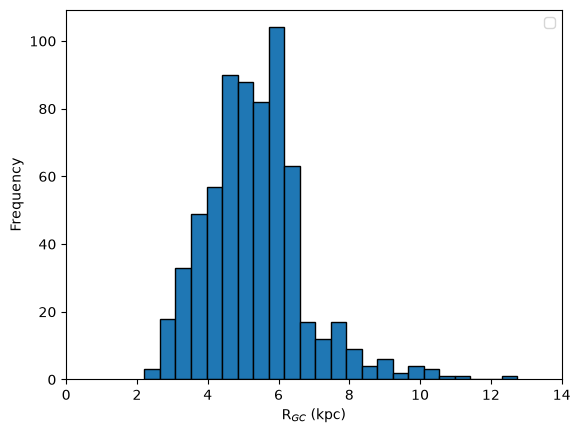

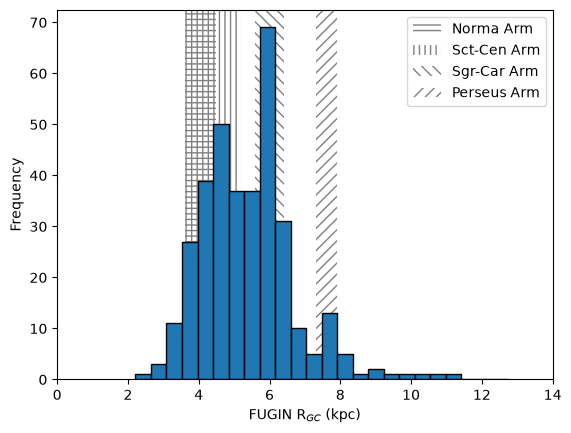

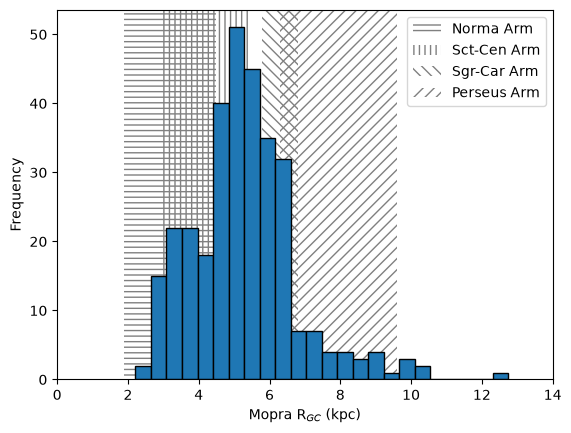

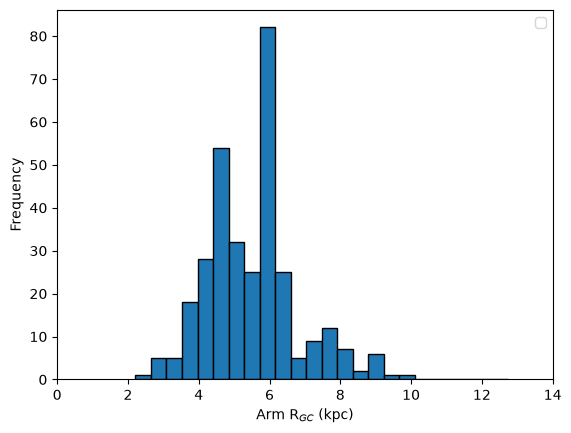

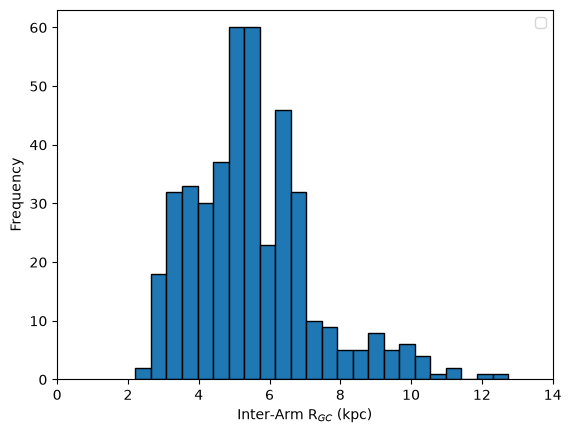

In [87]:
Rgc = df_ss['R_GC']

bins = np.linspace(
    Rgc.min(),
    Rgc.max(),
    int(np.sqrt(len(Rgc)))
)
xrange = [0, Rgc.max() * 1.1]
plt.hist(Rgc, bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel(r'R$_{GC}$ (kpc)')
plt.ylabel('Frequency')
plt.legend()

plt.figure()
plt.hist(df_F['R_GC'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel(r'FUGIN R$_{GC}$ (kpc)')
plt.ylabel('Frequency')
plt.axvspan(3.6, 4.5, facecolor='none',
            edgecolor='gray', hatch='---',
            linewidth=0, zorder=0, label = 'Norma Arm')
plt.axvspan(3.6, 5.2, facecolor='none',
            edgecolor='gray', hatch='|||',
            linewidth=0, zorder=0, label = 'Sct-Cen Arm')
plt.axvspan(5.6, 6.4, facecolor='none',
            edgecolor='gray', hatch='\\\\\\',
            linewidth=0, zorder=0, label = 'Sgr-Car Arm')
plt.axvspan(7.3, 7.9, facecolor='none',
            edgecolor='gray', hatch='///',
            linewidth=0, zorder=0, label = "Perseus Arm")
plt.legend()

plt.figure()
plt.hist(df_M['R_GC'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel(r'Mopra R$_{GC}$ (kpc)')
plt.ylabel('Frequency')
plt.axvspan(1.9, 4.5, facecolor='none',
            edgecolor='gray', hatch='---',
            linewidth=0, zorder=0, label = 'Norma Arm')
plt.axvspan(2.9, 5.4, facecolor='none',
            edgecolor='gray', hatch='|||',
            linewidth=0, zorder=0, label = 'Sct-Cen Arm')
plt.axvspan(5.8, 6.8, facecolor='none',
            edgecolor='gray', hatch='\\\\\\',
            linewidth=0, zorder=0, label = 'Sgr-Car Arm')
plt.axvspan(6.3, 9.6, facecolor='none',
            edgecolor='gray', hatch='///',
            linewidth=0, zorder=0, label = "Perseus Arm")
plt.legend()

plt.figure()
plt.hist(df_arm['R_GC'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel(r'Arm R$_{GC}$ (kpc)')
plt.ylabel('Frequency')
plt.legend()

plt.figure()
plt.hist(df_uns['R_GC'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel(r'Inter-Arm R$_{GC}$ (kpc)')
plt.ylabel('Frequency')
plt.legend()

#plt.savefig("/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/RGC_histogram_shaded.png")

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/845355753.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/845355753.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/845355753.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_91090/845355753.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore a

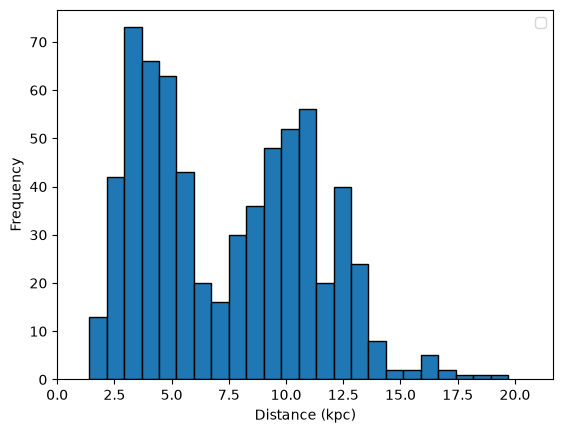

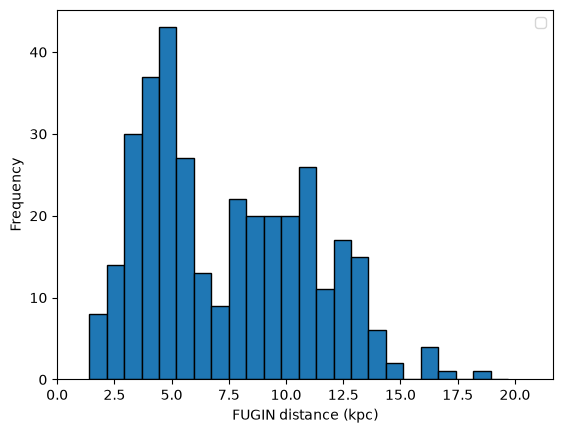

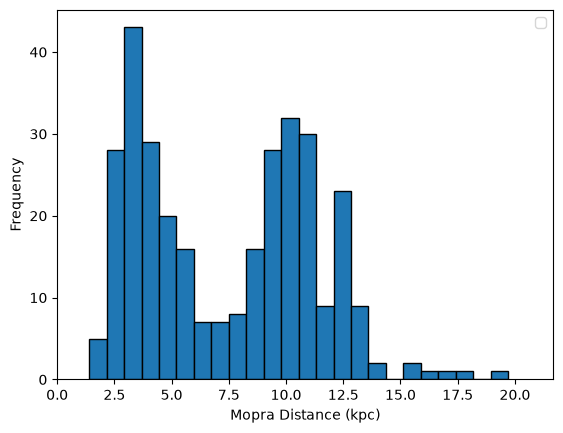

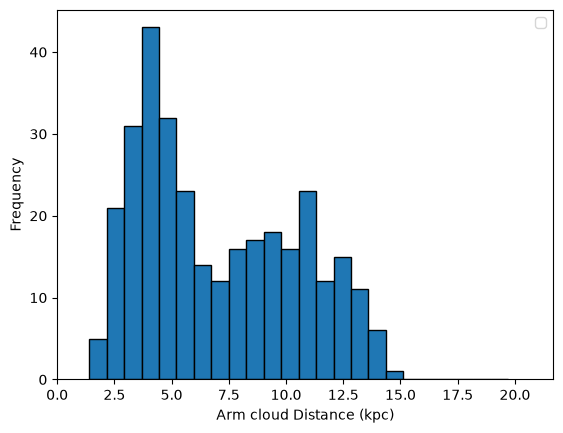

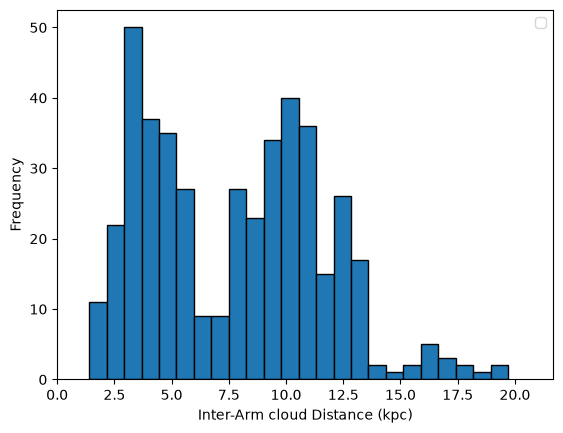

In [88]:
d_small = ds[ds < 20]

bins = np.linspace(
    d_small.min(),
    d_small.max(),
    int(np.sqrt(len(d_small)))
)
xrange = [0, d_small.max() * 1.1]
plt.hist(d_small, bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel('Distance (kpc)')
plt.ylabel('Frequency')
plt.legend()

plt.figure()
plt.hist(df_F['final_distance'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel('FUGIN distance (kpc)')
plt.ylabel('Frequency')
plt.legend()

plt.figure()
plt.hist(df_M['final_distance'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel('Mopra Distance (kpc)')
plt.ylabel('Frequency')
plt.legend()

plt.figure()
plt.hist(df_arm['final_distance'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel('Arm cloud Distance (kpc)')
plt.ylabel('Frequency')
plt.legend()

plt.figure()
plt.hist(df_uns['final_distance'], bins=bins, edgecolor='k')
plt.xlim(xrange)
plt.xlabel('Inter-Arm cloud Distance (kpc)')
plt.ylabel('Frequency')
plt.legend()

#plt.savefig("/Users/kyriakos.trakakis/Downloads/Mopra_FGN_project/Mopra/RGC_histogram_shaded.png")

(9181.818181818182, 4081000.0000000005)

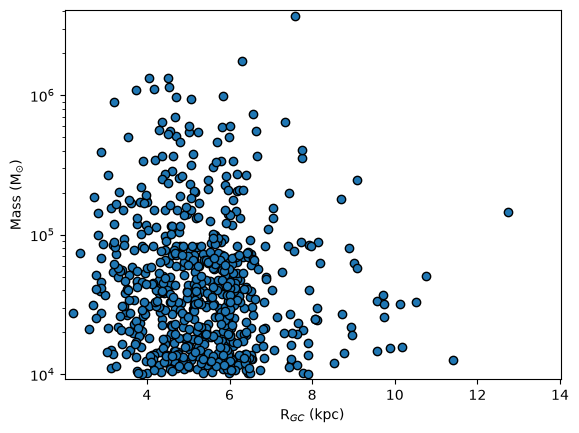

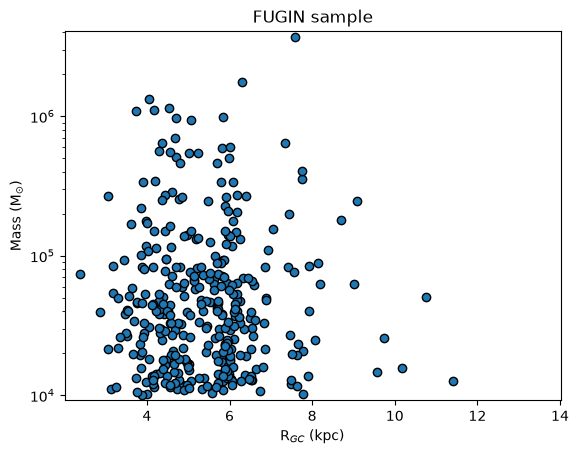

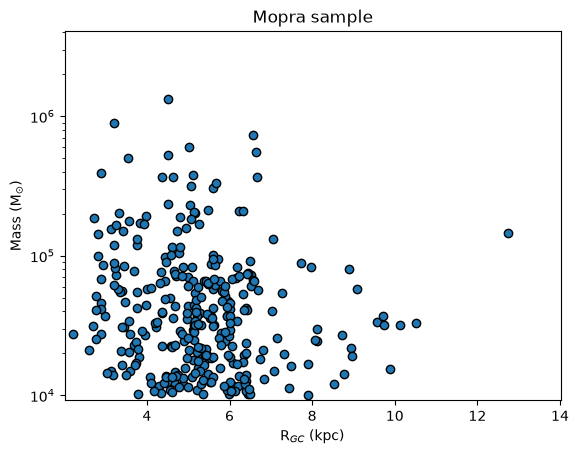

In [89]:
xrange = [Rgc.min() / 1.1, Rgc.max() * 1.1]
yrange = [Ms.min() / 1.1, Ms.max() * 1.1]

plt.scatter(Rgc, Ms, edgecolor = 'k')
plt.yscale('log')
plt.xlabel(r'R$_{GC}$ (kpc)')
plt.ylabel(r'Mass (M$_{\odot}$)')
plt.xlim(xrange)
plt.ylim(yrange)

plt.figure()
plt.scatter(df_F['R_GC'], df_F['X-mass'], edgecolor = 'k')
plt.yscale('log')
plt.xlabel(r'R$_{GC}$ (kpc)')
plt.ylabel(r'Mass (M$_{\odot}$)')
plt.title('FUGIN sample')
plt.xlim(xrange)
plt.ylim(yrange)

plt.figure()
plt.scatter(df_M['R_GC'], df_M['X-mass'], edgecolor = 'k')
plt.yscale('log')
plt.xlabel(r'R$_{GC}$ (kpc)')
plt.ylabel(r'Mass (M$_{\odot}$)')
plt.title('Mopra sample')
plt.xlim(xrange)
plt.ylim(yrange)


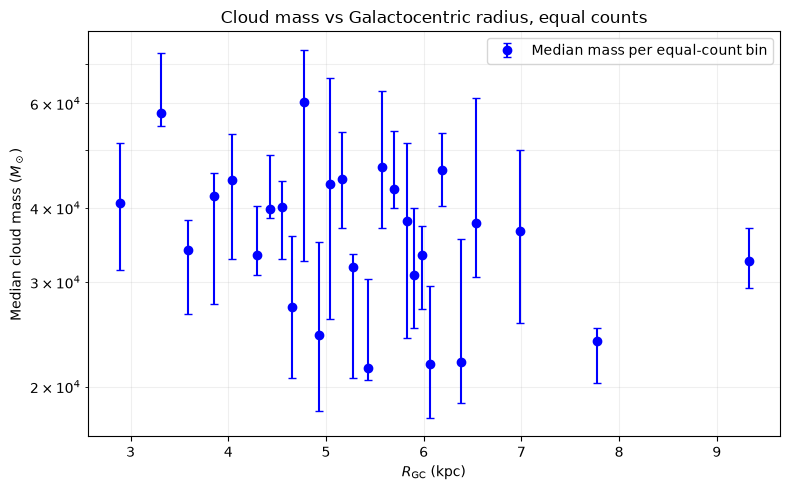

Counts per bin: [25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 24 24 24 24 24 24 24 24
 24 24 24]
Poisson count errors: [5.         5.         5.         5.         5.         5.
 5.         5.         5.         5.         5.         5.
 5.         5.         5.         5.         4.89897949 4.89897949
 4.89897949 4.89897949 4.89897949 4.89897949 4.89897949 4.89897949
 4.89897949 4.89897949 4.89897949]


In [90]:
# ----- 1. Prepare data -----
Rgc = np.asarray(Rgc, dtype=float)
Ms = np.asarray(Ms, dtype=float)

mask = np.isfinite(Rgc) & np.isfinite(Ms) & (Ms > 0)
Rgc, Ms = Rgc[mask], Ms[mask]

# ----- 2. Number of equal-count bins -----
N = len(Rgc)
num_bins = math.ceil(2 * N**0.4)

# Sort both arrays by Rgc
order = np.argsort(Rgc)
R_sorted = Rgc[order]
M_sorted = Ms[order]

# Split into approximately equal-count groups
groups = np.array_split(np.arange(N), num_bins)  ## Splits the 663 entries into 27 groups, [0-24], [25-49] etc

# ----- 3. Bin statistics -----
R_medians = np.array([
    np.median(R_sorted[g]) for g in groups
])

M_medians = np.array([
    np.median(M_sorted[g]) for g in groups
])

counts = np.array([len(g) for g in groups])
poisson_err = np.sqrt(counts)

# ----- 4. Bootstrap errors on median mass -----
rng = np.random.default_rng()
n_boot = 1000

M_err_low = []
M_err_high = []

for g in groups:
    masses = M_sorted[g]

    boot_medians = np.median(
        rng.choice(
            masses,
            size=(n_boot, len(masses)),
            replace=True
        ),
        axis=1
    )

    low, high = np.percentile(
        boot_medians, [16, 84]
    )

    median = np.median(masses)

    M_err_low.append(median - low)
    M_err_high.append(high - median)

M_errors = np.array([M_err_low, M_err_high])

# ----- 5. Plot -----
plt.figure(figsize=(8, 5))

plt.errorbar(
    R_medians,
    M_medians,
    yerr=M_errors,  # can be M_errors for bootstrapping or poisson_err for number of counts
    fmt='o',
    capsize=3,
    color='blue',
    label='Median mass per equal-count bin'
)

plt.xlabel(r'$R_{\mathrm{GC}}$ (kpc)')
plt.ylabel(r'Median cloud mass ($M_\odot$)')
plt.yscale('log')
plt.title('Cloud mass vs Galactocentric radius, equal counts')
plt.grid(True, which='both', alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

print("Counts per bin:", counts)
print("Poisson count errors:", poisson_err)

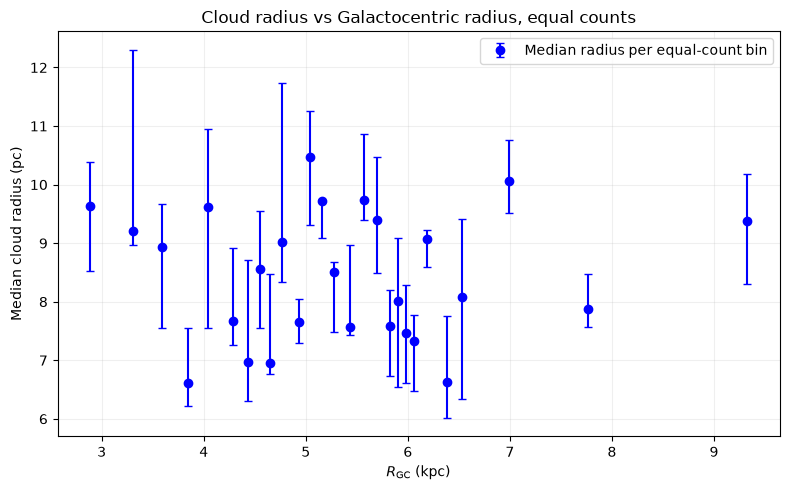

Counts per bin: [25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 24 24 24 24 24 24 24 24
 24 24 24]
Poisson count errors: [5.         5.         5.         5.         5.         5.
 5.         5.         5.         5.         5.         5.
 5.         5.         5.         5.         4.89897949 4.89897949
 4.89897949 4.89897949 4.89897949 4.89897949 4.89897949 4.89897949
 4.89897949 4.89897949 4.89897949]


In [91]:
# ----- 1. Prepare data -----
Rgc = np.asarray(Rgc, dtype=float)
Rs = np.asarray(Rs, dtype=float)

mask = np.isfinite(Rgc) & np.isfinite(Rs) & (Rs > 0)
Rgc, Rs = Rgc[mask], Rs[mask]

# ----- 2. Number of equal-count bins -----
N = len(Rgc)
num_bins = math.ceil(2 * N**0.4)

# Sort both arrays by Rgc
order = np.argsort(Rgc)
Rgc_sorted = Rgc[order]
R_sorted = Rs[order]

# Split into approximately equal-count groups
groups = np.array_split(np.arange(N), num_bins)  ## Splits the 663 entries into 27 groups, [0-24], [25-49] etc

# ----- 3. Bin statistics -----
Rgc_medians = np.array([
    np.median(Rgc_sorted[g]) for g in groups
])

R_medians = np.array([
    np.median(R_sorted[g]) for g in groups
])

counts = np.array([len(g) for g in groups])
poisson_err = np.sqrt(counts)

# ----- 4. Bootstrap errors on median mass -----
rng = np.random.default_rng()
n_boot = 1000

R_err_low = []
R_err_high = []

for g in groups:
    masses = R_sorted[g]

    boot_medians = np.median(
        rng.choice(
            masses,
            size=(n_boot, len(masses)),
            replace=True
        ),
        axis=1
    )

    low, high = np.percentile(
        boot_medians, [16, 84]
    )

    median = np.median(masses)

    R_err_low.append(median - low)
    R_err_high.append(high - median)

R_errors = np.array([R_err_low, R_err_high])

# ----- 5. Plot -----
plt.figure(figsize=(8, 5))

plt.errorbar(
    Rgc_medians,
    R_medians,
    yerr=R_errors,  # can be M_errors for bootstrapping or poisson_err for number of counts
    fmt='o',
    capsize=3,
    color='blue',
    label='Median radius per equal-count bin'
)

plt.xlabel(r'$R_{\mathrm{GC}}$ (kpc)')
plt.ylabel('Median cloud radius (pc)')
#plt.yscale('log')
plt.title('Cloud radius vs Galactocentric radius, equal counts')
plt.grid(True, which='both', alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

print("Counts per bin:", counts)
print("Poisson count errors:", poisson_err)

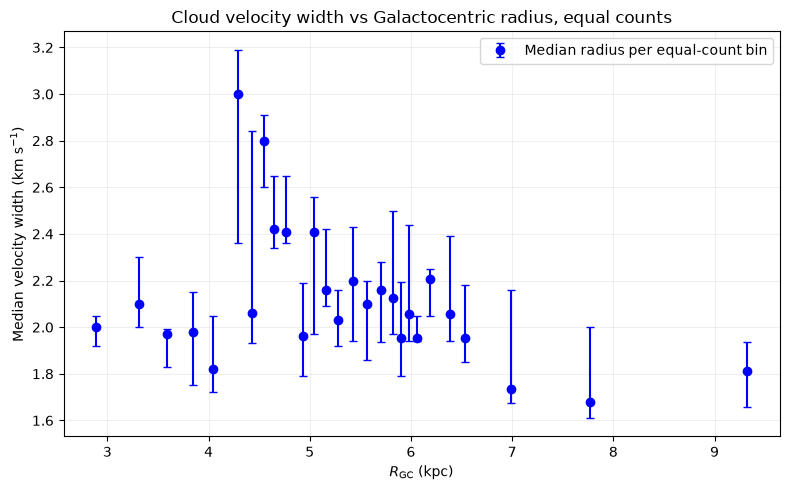

Counts per bin: [25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 24 24 24 24 24 24 24 24
 24 24 24]
Poisson count errors: [5.         5.         5.         5.         5.         5.
 5.         5.         5.         5.         5.         5.
 5.         5.         5.         5.         4.89897949 4.89897949
 4.89897949 4.89897949 4.89897949 4.89897949 4.89897949 4.89897949
 4.89897949 4.89897949 4.89897949]


In [92]:
# ----- 1. Prepare data -----
Rgc = np.asarray(Rgc, dtype=float)
ss = np.asarray(ss, dtype=float)

mask = np.isfinite(Rgc) & np.isfinite(ss) & (ss > 0)
Rgc, ss = Rgc[mask], ss[mask]

# ----- 2. Number of equal-count bins -----
N = len(Rgc)
num_bins = math.ceil(2 * N**0.4)

# Sort both arrays by Rgc
order = np.argsort(Rgc)
Rgc_sorted = Rgc[order]
s_sorted = ss[order]

# Split into approximately equal-count groups
groups = np.array_split(np.arange(N), num_bins)  ## Splits the 663 entries into 27 groups, [0-24], [25-49] etc

# ----- 3. Bin statistics -----
Rgc_medians = np.array([
    np.median(Rgc_sorted[g]) for g in groups
])

s_medians = np.array([
    np.median(s_sorted[g]) for g in groups
])

counts = np.array([len(g) for g in groups])
poisson_err = np.sqrt(counts)

# ----- 4. Bootstrap errors on median mass -----
rng = np.random.default_rng()
n_boot = 1000

s_err_low = []
s_err_high = []

for g in groups:
    masses = s_sorted[g]

    boot_medians = np.median(
        rng.choice(
            masses,
            size=(n_boot, len(masses)),
            replace=True
        ),
        axis=1
    )

    low, high = np.percentile(
        boot_medians, [16, 84]
    )

    median = np.median(masses)

    s_err_low.append(median - low)
    s_err_high.append(high - median)

s_errors = np.array([s_err_low, s_err_high])

# ----- 5. Plot -----
plt.figure(figsize=(8, 5))

plt.errorbar(
    Rgc_medians,
    s_medians,
    yerr=s_errors,  # can be M_errors for bootstrapping or poisson_err for number of counts
    fmt='o',
    capsize=3,
    color='blue',
    label='Median radius per equal-count bin'
)

plt.xlabel(r'$R_{\mathrm{GC}}$ (kpc)')
plt.ylabel(r'Median velocity width (km s$^{-1}$)')
#plt.yscale('log')
plt.title('Cloud velocity width vs Galactocentric radius, equal counts')
plt.grid(True, which='both', alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

print("Counts per bin:", counts)
print("Poisson count errors:", poisson_err)

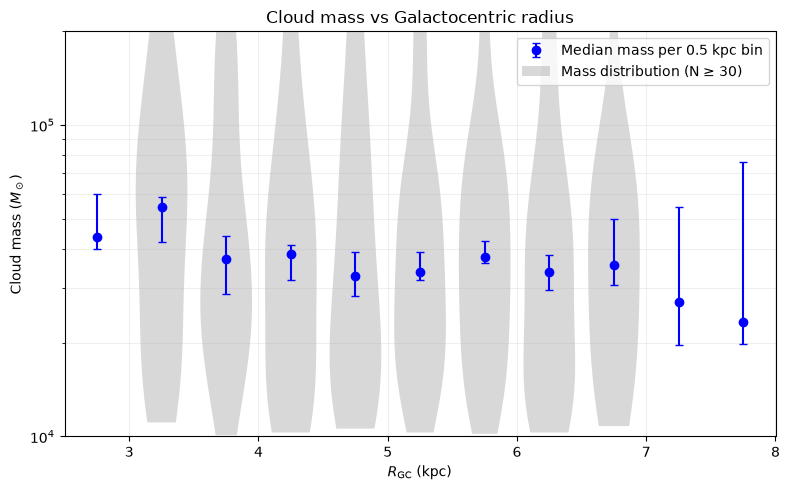

Bin centres: [2.75 3.25 3.75 4.25 4.75 5.25 5.75 6.25 6.75 7.25 7.75]
Counts per bin: [ 16  34  56  72  96 100 111  86  31  15  17]
[43750. 54700. 37200. 38600. 32850. 33700. 37700. 33650. 35600. 27000.
 23400.]


In [114]:
# ----- 1. Prepare data -----
Rgc = np.asarray(Rgc, dtype=float)
Ms  = np.asarray(Ms, dtype=float)
mask = np.isfinite(Rgc) & np.isfinite(Ms) & (Ms > 0)
Rgc, Ms = Rgc[mask], Ms[mask]

# ----- 2. Equal-width bins -----
bw = 0.5
min_median, min_violin = 10, 30
edges = np.arange(np.floor(Rgc.min()/bw)*bw, np.ceil(Rgc.max()/bw)*bw + bw, bw)
idx = np.digitize(Rgc, edges) - 1

bins = [(i, np.where(idx == i)[0]) for i in range(len(edges) - 1)]
bins = [(i, g) for i, g in bins if len(g) >= min_median]

centres   = np.array([0.5*(edges[i] + edges[i+1]) for i, _ in bins])
M_medians = np.array([np.median(Ms[g]) for _, g in bins])
counts    = np.array([len(g) for _, g in bins])

# ----- 3. Bootstrap errors on median mass -----
rng = np.random.default_rng()
n_boot = 1000
err_low, err_high = [], []
for _, g in bins:
    m = Ms[g]
    boot = np.median(rng.choice(m, size=(n_boot, len(m)), replace=True), axis=1)
    lo, hi = np.percentile(boot, [16, 84])
    err_low.append(np.median(m) - lo)
    err_high.append(hi - np.median(m))
M_errors = np.array([err_low, err_high])

# ----- 4. Plot -----
fig, ax = plt.subplots(figsize=(8, 5))

half = 0.4 * bw
for i, g in bins:
    if len(g) < min_violin:
        continue
    logm = np.log10(Ms[g])
    y = np.linspace(logm.min(), logm.max(), 200)
    d = gaussian_kde(logm)(y)
    d = d / d.max() * half
    xc = 0.5 * (edges[i] + edges[i+1])
    ax.fill_betweenx(10**y, xc - d, xc + d, color='gray', alpha=0.3, lw=0, zorder=1)

ax.errorbar(centres, M_medians, yerr=M_errors, fmt='o', capsize=3,
            color='blue', zorder=3, label=f'Median mass per {bw} kpc bin')

ax.set_xlabel(r'$R_{\mathrm{GC}}$ (kpc)')
ax.set_ylabel(r'Cloud mass ($M_\odot$)')
ax.set_yscale('log')
ax.set_title('Cloud mass vs Galactocentric radius')
ax.grid(True, which='both', alpha=0.2)

handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor='gray', alpha=0.3,
                     label=f'Mass distribution (N ≥ {min_violin})'))
ax.legend(handles=handles)
plt.ylim([10000, 200000])
plt.tight_layout()
plt.show()

print("Bin centres:", centres)
print("Counts per bin:", counts)
print(M_medians)

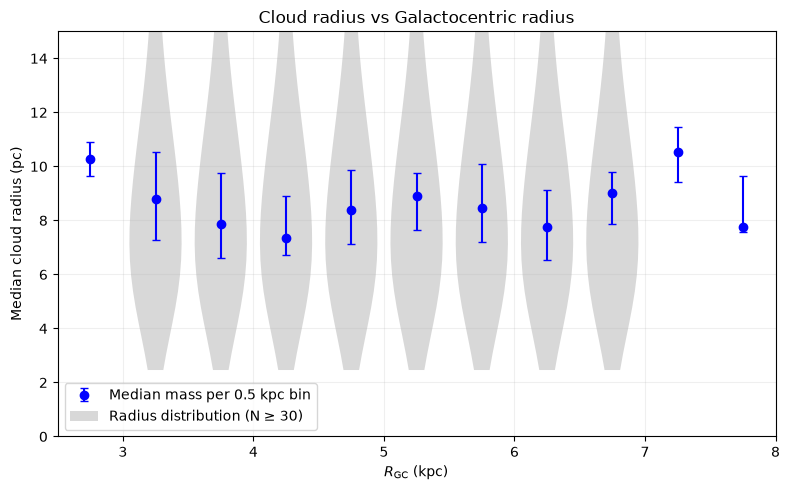

Bin centres: [2.75 3.25 3.75 4.25 4.75 5.25 5.75 6.25 6.75 7.25 7.75]
Counts per bin: [ 16  34  56  72  96 100 111  86  31  15  17]


In [121]:
# ----- 2. Equal-width bins -----
bw = 0.5
min_median, min_violin = 10, 30
edges = np.arange(np.floor(Rgc.min()/bw)*bw, np.ceil(Rgc.max()/bw)*bw + bw, bw)
idx = np.digitize(Rgc, edges) - 1

bins = [(i, np.where(idx == i)[0]) for i in range(len(edges) - 1)]
bins = [(i, g) for i, g in bins if len(g) >= min_median]

centres   = np.array([0.5*(edges[i] + edges[i+1]) for i, _ in bins])
R_medians = np.array([np.median(Rs[g]) for _, g in bins])
counts    = np.array([len(g) for _, g in bins])

# ----- 3. Bootstrap errors on median mass -----
rng = np.random.default_rng()
n_boot = 1000
err_low, err_high = [], []
for _, g in bins:
    r = Rs[g]
    boot = np.median(rng.choice(r, size=(n_boot, len(m)), replace=True), axis=1)
    lo, hi = np.percentile(boot, [16, 84])
    err_low.append(np.median(r) - lo)
    err_high.append(hi - np.median(r))
R_errors = np.array([err_low, err_high])

# ----- 4. Plot -----
fig, ax = plt.subplots(figsize=(8, 5))

half = 0.4 * bw
for i, g in bins:
    if len(g) < min_violin:
        continue
    y = np.linspace(Rs.min(), Rs.max(), 200)
    d = gaussian_kde(Rs)(y)
    d = d / d.max() * half
    xc = 0.5 * (edges[i] + edges[i+1])
    ax.fill_betweenx(y, xc - d, xc + d, color='gray', alpha=0.3, lw=0, zorder=1)

ax.errorbar(centres, R_medians, yerr=R_errors, fmt='o', capsize=3,
            color='blue', zorder=3, label=f'Median mass per {bw} kpc bin')

ax.set_xlabel(r'$R_{\mathrm{GC}}$ (kpc)')
plt.ylabel('Median cloud radius (pc)')
ax.set_title('Cloud radius vs Galactocentric radius')
ax.grid(True, which='both', alpha=0.2)

handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor='gray', alpha=0.3,
                     label=f'Radius distribution (N ≥ {min_violin})'))
ax.legend(handles=handles)
plt.ylim([0, 15])
plt.tight_layout()
plt.show()

print("Bin centres:", centres)
print("Counts per bin:", counts)

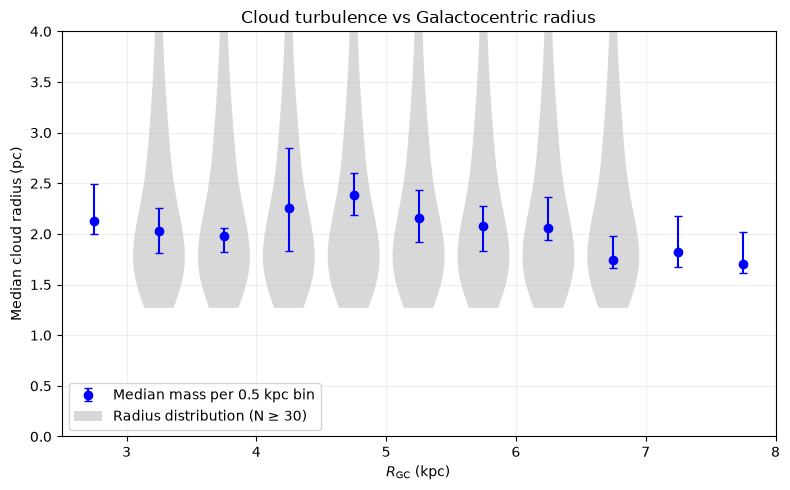

Bin centres: [2.75 3.25 3.75 4.25 4.75 5.25 5.75 6.25 6.75 7.25 7.75]
Counts per bin: [ 16  34  56  72  96 100 111  86  31  15  17]


In [123]:
# ----- 2. Equal-width bins -----
bw = 0.5
min_median, min_violin = 10, 30
edges = np.arange(np.floor(Rgc.min()/bw)*bw, np.ceil(Rgc.max()/bw)*bw + bw, bw)
idx = np.digitize(Rgc, edges) - 1

bins = [(i, np.where(idx == i)[0]) for i in range(len(edges) - 1)]
bins = [(i, g) for i, g in bins if len(g) >= min_median]

centres   = np.array([0.5*(edges[i] + edges[i+1]) for i, _ in bins])
s_medians = np.array([np.median(ss[g]) for _, g in bins])
counts    = np.array([len(g) for _, g in bins])

# ----- 3. Bootstrap errors on median mass -----
rng = np.random.default_rng()
n_boot = 1000
err_low, err_high = [], []
for _, g in bins:
    s = ss[g]
    boot = np.median(rng.choice(s, size=(n_boot, len(m)), replace=True), axis=1)
    lo, hi = np.percentile(boot, [16, 84])
    err_low.append(np.median(s) - lo)
    err_high.append(hi - np.median(s))
s_errors = np.array([err_low, err_high])

# ----- 4. Plot -----
fig, ax = plt.subplots(figsize=(8, 5))

half = 0.4 * bw
for i, g in bins:
    if len(g) < min_violin:
        continue
    y = np.linspace(ss.min(), ss.max(), 200)
    d = gaussian_kde(ss)(y)
    d = d / d.max() * half
    xc = 0.5 * (edges[i] + edges[i+1])
    ax.fill_betweenx(y, xc - d, xc + d, color='gray', alpha=0.3, lw=0, zorder=1)

ax.errorbar(centres, s_medians, yerr=s_errors, fmt='o', capsize=3,
            color='blue', zorder=3, label=f'Median mass per {bw} kpc bin')

ax.set_xlabel(r'$R_{\mathrm{GC}}$ (kpc)')
plt.ylabel('Median cloud radius (pc)')
ax.set_title('Cloud turbulence vs Galactocentric radius')
ax.grid(True, which='both', alpha=0.2)

handles, labels = ax.get_legend_handles_labels()
handles.append(Patch(facecolor='gray', alpha=0.3,
                     label=f'Radius distribution (N ≥ {min_violin})'))
ax.legend(handles=handles)
plt.ylim([0, 4])
plt.tight_layout()
plt.show()

print("Bin centres:", centres)
print("Counts per bin:", counts)